# 📊 Exploration autonome

> ✍️ **Notebook dirigé** · complétez les cellules marquées ✍️ À VOUS.

**Jour 1 · 9h15** · 30 minutes, sans consignes techniques

*Analyse exploratoire et interprétation métier*

**Objectifs**
- Faire un diagnostic rapide de votre jeu de données
- Identifier les variables clés pour le commanditaire
- Formuler trois premières hypothèses

## Le principe
Pendant 30 minutes, vous explorez **comme vous voulez**. Aucune consigne technique : seulement des questions auxquelles répondre à la fin.

1. Que représente une ligne ?
2. Quelle période, combien de clients, combien de lignes ?
3. Quelles variables comptent pour le commanditaire de votre brief ?
4. Quels problèmes de qualité voyez-vous ?
5. Quelles **trois hypothèses** voulez-vous tester aujourd'hui ?

In [27]:
# ⚙️ À exécuter en premier : récupère la configuration du cours (quelques secondes)
import os, sys
CONFIG_ID = "1bW5RsToUHc-7pGiyHS_1B2OYkAFsrv3r"

# Suppression du fichier corrompu s'il existe
if os.path.exists("config_projet.py"):
    os.remove("config_projet.py")

# Téléchargement propre avec gdown pour contourner l'avertissement de virus Google Drive
!gdown --id {CONFIG_ID} -O config_projet.py

print("✅ Configuration prête : chaque fichier de données se télécharge au premier usage")

/usr/local/lib/python3.13/dist-packages/gdown/__main__.py:139: FutureWarning: Option `--id` was deprecated in version 4.3.1 and will be removed in 5.0. You don't need to pass it anymore to use a file ID.
  warnings.warn(
Downloading...
From (original): https://drive.google.com/uc?id=1bW5RsToUHc-7pGiyHS_1B2OYkAFsrv3r
From (redirected): https://drive.google.com/uc?id=1bW5RsToUHc-7pGiyHS_1B2OYkAFsrv3r&confirm=t&uuid=30a39680-b7e2-4e4b-b59e-7b89dea19cf0
To: /content/config_projet.py
100% 6.94k/6.94k [00:00<00:00, 20.3MB/s]
✅ Configuration prête : chaque fichier de données se télécharge au premier usage


In [28]:
# Choisissez votre secteur : "commerce", "banque" ou "hotellerie"
SECTEUR = "commerce"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from config_projet import charger, reference, nettoyage_minimal

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)
brut, cfg = charger(SECTEUR)
print(cfg["nom"], "·", brut.shape[0], "lignes,", brut.shape[1], "colonnes")

Maison Lumen · 24224 lignes, 16 colonnes


In [29]:
from config_projet import brief
brief(SECTEUR)

# Brief · Maison Lumen

> Entreprise et données fictives, conçues pour la formation.

## Le commanditaire
**Camille Roux, directrice marketing et e-commerce.** Maison Lumen vend luminaires, textile, mobilier, décoration et cuisine dans 38 magasins, sur son site et, depuis peu, sur une application.

## Le contexte
- Le 15 avril 2024, le site a été refondu et l'application lancée. La direction veut savoir ce que cela a vraiment changé.
- Depuis 2023, un algorithme de propension choisit chaque semaine les clients qui reçoivent une **offre personnalisée**. Le service client remonte des plaintes de clients âgés qui « ne reçoivent jamais rien ».
- Le comité de direction arbitre en janvier le budget marketing de l'année.

## La demande
1. Comment évolue le chiffre d'affaires ? Quelle saisonnalité, quel effet de la refonte d'avril 2024 ?
2. Quels canaux, catégories et profils de clients portent la croissance ?
3. L'algorithme d'offres personnalisées traite-t-il tous les clients de façon équitable ? Notre clientèle est-elle représentative ?
4. Que recommandez-vous pour 2026, avec quels indicateurs de suivi, y compris environnementaux et sociaux ?

## Les données · `commerce_maison_lumen.csv`
Une ligne = une commande, de janvier 2023 à décembre 2025.

| Colonne | Description |
|---|---|
| `date_commande` | Date de la commande |
| `commande_id`, `client_id` | Identifiants |
| `genre`, `age`, `tranche_age` | Profil déclaré à l'inscription au programme client |
| `region` | Zone de résidence du client |
| `canal` | `magasin`, `web` ou `app` |
| `categorie` | Famille de produits |
| `montant_eur` | Montant TTC payé, remise déduite (négatif pour un avoir) |
| `remise_pct` | Remise appliquée, en % |
| `carte_fidelite` | 1 si le client a la carte de fidélité |
| `note_satisfaction` | Note de 1 à 5 laissée après l'achat (facultative) |
| `retour` | 1 si au moins un article a été retourné |
| `offre_personnalisee` | 1 si l'algorithme a envoyé une offre au client dans le mois précédent |
| `rachat_90j` | 1 si le client a racheté dans les 90 jours |

`reference_population.csv` donne la répartition de la population française adulte (approximation pédagogique inspirée de l'INSEE).


In [30]:
# ✍️ À VOUS : remplacez les ... et traitez les TODO
# Votre exploration, autant de cellules que nécessaire


## Vos réponses
1. Une ligne = …
2. Période et volumes : …
3. Variables clés : …
4. Problèmes de qualité : …
5. Hypothèses : H1 … H2 … H3 …

💾 **Versionnez** : *Fichier › Enregistrer une copie dans GitHub*, message de commit : « Exploration : hypothèses H1 à H3 »

In [31]:
display(brut.head())
display(cfg)

,date_commande,commande_id,client_id,genre,age,tranche_age,region,canal,categorie,montant_eur,remise_pct,carte_fidelite,note_satisfaction,retour,offre_personnalisee,rachat_90j
0,2023-01-01,CMD000000,ML04162,H,35,35-44,Île-de-France,magasin,Luminaire,97.01,20,0,NaN,0,1,1
1,2023-01-01,CMD000016,ML01192,F,51,45-54,Nord-Est,web,Textile,51.90,20,0,2.0,1,1,0
2,2023-01-01,CMD000015,ML00594,F,25,25-34,Ouest,app,Cuisine,40.73,20,1,4.0,0,0,0
3,2023-01-01,CMD000014,ML08607,H,29,25-34,Nord-Est,web,Textile,48.74,10,1,3.0,0,1,0
4,2023-01-01,CMD000013,ML00599,H,20,18-24,Sud-Ouest,web,Cuisine,35.60,30,1,4.0,0,0,0


{'nom': 'Maison Lumen',
 'fichier': 'commerce_maison_lumen.csv',
 'dates': ['date_commande'],
 'date': 'date_commande',
 'ca': 'montant_eur',
 'ca_label': "Chiffre d'affaires (€)",
 'id': 'commande_id',
 'decision': 'offre_personnalisee',
 'decision_label': 'offre personnalisée envoyée',
 'resultat': 'rachat_90j',
 'sensibles': ['tranche_age', 'genre', 'region'],
 'segment': 'canal',
 'evenement': ('2024-04-15', "refonte du site et lancement de l'app"),
 'atypiques': []}

In [32]:
# une ligne

In [33]:
display(brut.shape)

(24224, 16)

#Notre datset comprend 24224 lignes et 16 colonnes.

In [34]:
display(brut.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 24224 entries, 0 to 24223
Data columns (total 16 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   date_commande        24224 non-null  datetime64[ns]
 1   commande_id          24224 non-null  object        
 2   client_id            24224 non-null  object        
 3   genre                24224 non-null  object        
 4   age                  24224 non-null  int64         
 5   tranche_age          24224 non-null  object        
 6   region               23983 non-null  object        
 7   canal                24224 non-null  object        
 8   categorie            24224 non-null  object        
 9   montant_eur          24224 non-null  float64       
 10  remise_pct           24224 non-null  int64         
 11  carte_fidelite       24224 non-null  int64         
 12  note_satisfaction    10835 non-null  float64       
 13  retour               24224 non-

None

In [35]:
print('total des variables(classe) catégorielles :')
display(brut.select_dtypes(include="object").shape[1])
print('total des variables(classe) numérique :')
display(brut.select_dtypes(include=["int64","float64"]).shape[1])

total des variables(classe) catégorielles :


7

total des variables(classe) numérique :


8

# Cet dataset est commposé de 7 colonnes qui sont catégorielles et 8 sont des classes numérque

In [36]:
display(brut.isnull().sum()/brut.shape[0]*100)

,0
date_commande,0.000000
commande_id,0.000000
client_id,0.000000
genre,0.000000
age,0.000000
tranche_age,0.000000
region,0.994881
canal,0.000000
categorie,0.000000
montant_eur,0.000000


# dans la donnée commerce on constacte que deux variables qui detiennent des valeurs manquantes.Region contient 241/24224 de valeur manquantes soit 0.99% et note de satisfaction qui a 13389 valeurs manquantes soit 55,27% de l'ensemble des donnés

In [37]:
# represente une ligne
display(brut['date_commande'].is_unique)

False

# Cela met en évidence que plusieurs lignes de commandes partagent exactement la meme date ou heure de commande, ce qui conrrespond à une spécificité des sites e-commerce.

In [38]:
print("min", brut['date_commande'].min())
print("max", brut['date_commande'].max())

min 2023-01-01 00:00:00
max 2025-12-31 00:00:00


In [39]:
brut['client_id'].nunique()

6768

# Période : Du 1er janvier 2023 au 31 décembre 2025 (3 ans).
# Nombre de clients uniques : 6 768 clients.

In [40]:
# Variables clés
print("VARIABLE CIBLE (Chiffre d'affaires) :", cfg['ca'])
print("VARIABLE DE DÉCISION (Action marketing) :", cfg['decision'])
print("VARIABLE DE RÉSULTAT (Objectif) :", cfg['resultat'])
print("VARIABLES SENSIBLES (Équité/Segmentation) :", cfg['sensibles'])
print("VARIABLE DE SEGMENTATION (Canal d'acquisition) :", cfg['segment'])

VARIABLE CIBLE (Chiffre d'affaires) : montant_eur
VARIABLE DE DÉCISION (Action marketing) : offre_personnalisee
VARIABLE DE RÉSULTAT (Objectif) : rachat_90j
VARIABLES SENSIBLES (Équité/Segmentation) : ['tranche_age', 'genre', 'region']
VARIABLE DE SEGMENTATION (Canal d'acquisition) : canal


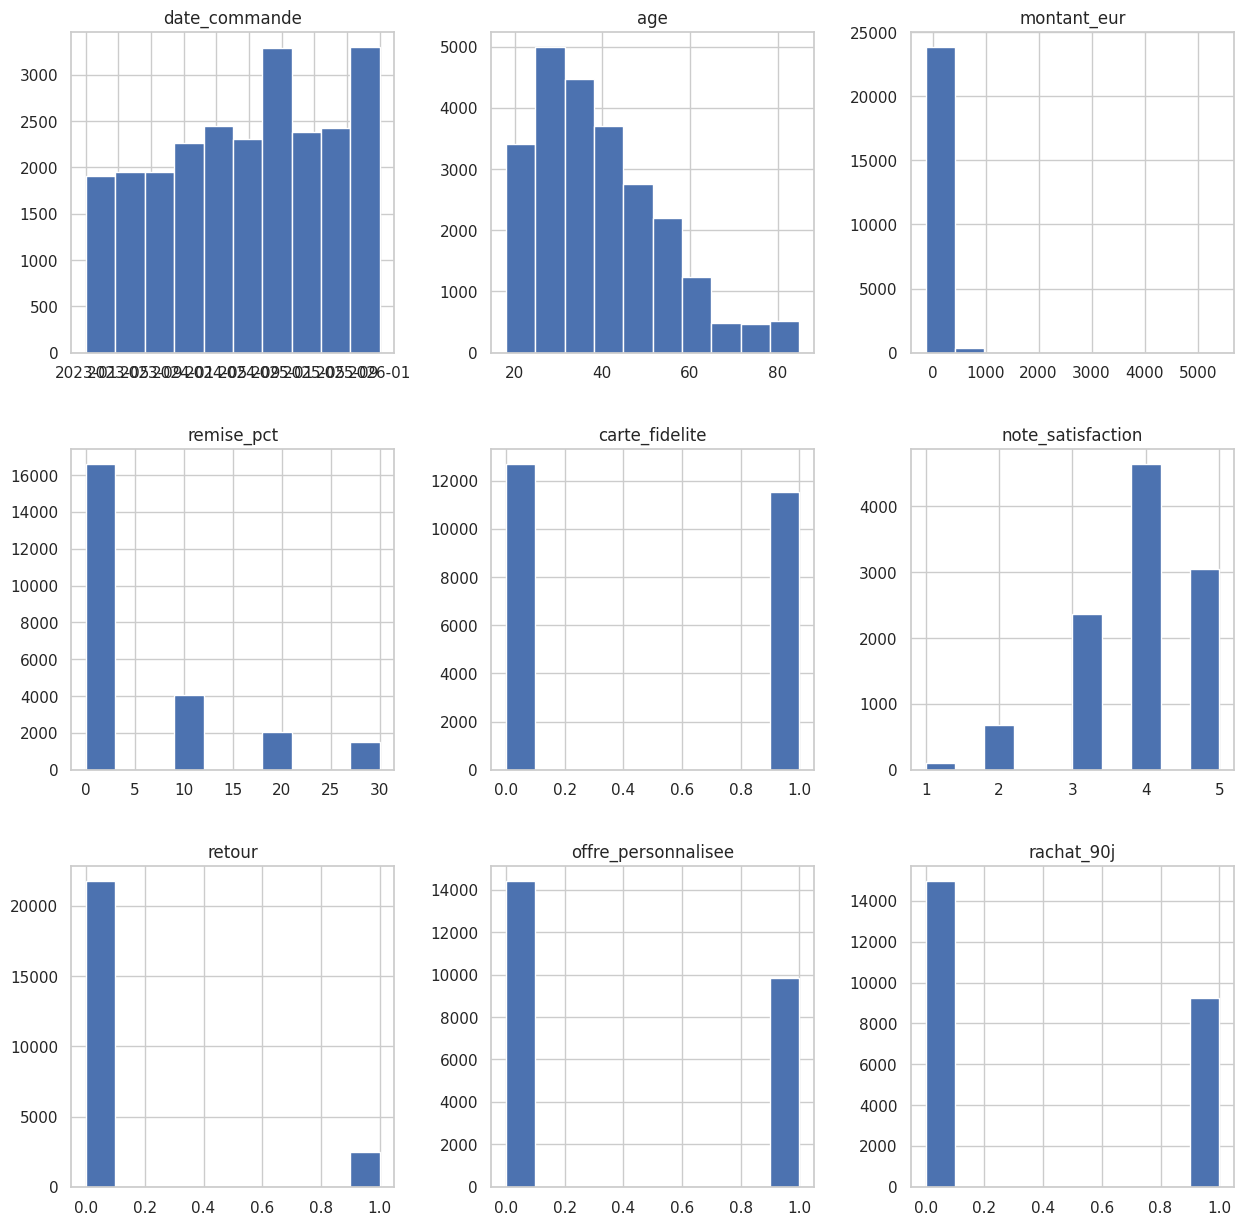

In [41]:
# visualisation retour par histogramme
brut.hist(figsize=(15,15))
plt.show()

#Les variables date, âge, remise et les indicateurs 0/1 sont propres et directement utilisables.
#montant_eur demande une inspection (valeurs extrêmes probables) avant toute moyenne.
#note_satisfaction est inutilisable sur l'ensemble du jeu : elle ne couvre que 45 % des lignes.

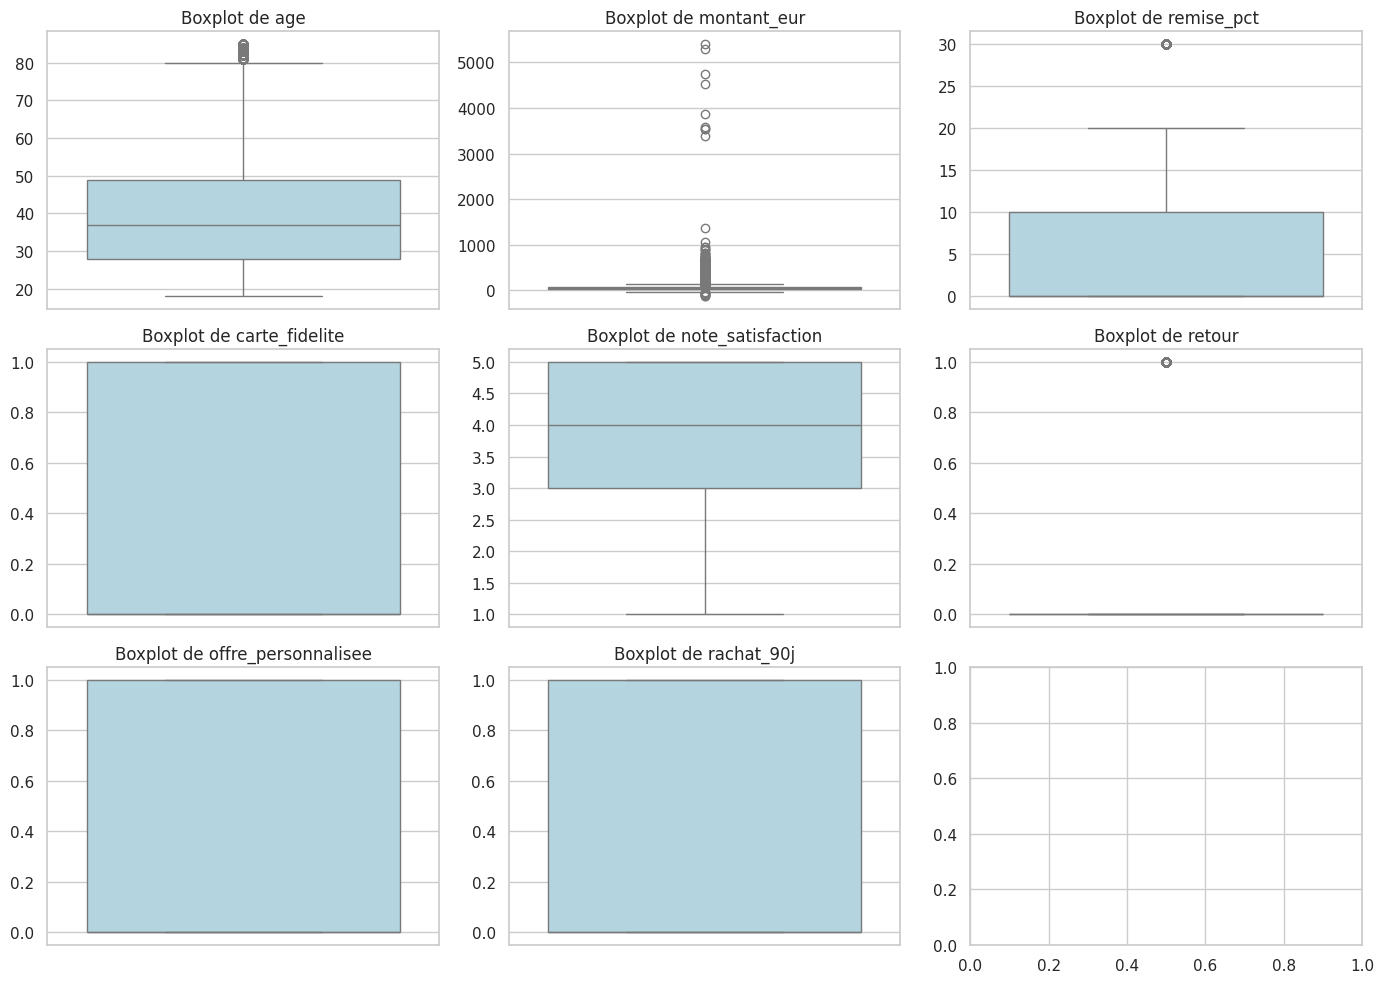

In [42]:
# Identifier les colonnes numériques continues
colonnes_numeriques = brut.select_dtypes(include=["int64", "float64"]).columns

# Tracer un boxplot pour chaque variable avec sa propre échelle
fig, axes = plt.subplots(3, 3, figsize=(14, 10))
axes = axes.flatten()

for i, col in enumerate(colonnes_numeriques):
    sns.boxplot(data=brut, y=col, ax=axes[i], color='lightblue')
    axes[i].set_title(f'Boxplot de {col}')
    axes[i].set_ylabel('')

plt.tight_layout()
plt.show()

In [43]:
#les doublons
display(brut.duplicated().sum())

np.int64(121)

# Nous avons dans ce jeu de données 121 lignes complètement identiques soit une proportion de 0,5%.

In [44]:
# Suppression des doublons parfaits
print(f"Taille avant suppression : {brut.shape}")
brut = brut.drop_duplicates()
print(f"Taille après suppression : {brut.shape}")

Taille avant suppression : (24224, 16)
Taille après suppression : (24103, 16)


# Après la suppression doublons, nous aurons 24103 lignes et 16 colonnes.

In [45]:
# Calcul du taux de réachat moyen selon la réception d'une offre personnalisée
impact_offre = brut.groupby('offre_personnalisee')['rachat_90j'].mean().reset_index()
impact_offre['rachat_pct'] = impact_offre['rachat_90j'] * 100
impact_offre['offre_label'] = impact_offre['offre_personnalisee'].map({0: 'Sans offre', 1: 'Avec offre'})

display(impact_offre[['offre_label', 'rachat_pct']])

,offre_label,rachat_pct
0,Sans offre,34.178187
1,Avec offre,44.167263


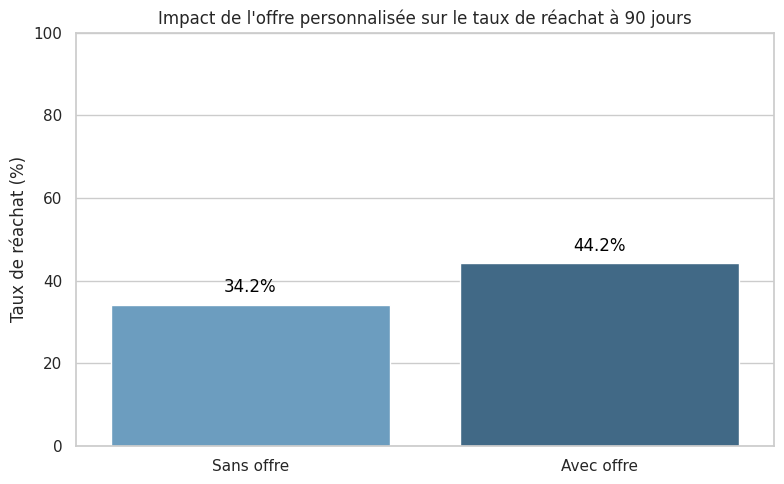

In [46]:
# Visualisation de l'impact sous forme de diagramme en barres
plt.figure(figsize=(8, 5))
sns.barplot(data=impact_offre, x='offre_label', y='rachat_pct', hue='offre_label', palette='Blues_d', legend=False)
plt.title("Impact de l'offre personnalisée sur le taux de réachat à 90 jours")
plt.ylabel('Taux de réachat (%)')
plt.xlabel('')
plt.ylim(0, 100)

# Ajout des valeurs sur les barres
for index, row in impact_offre.iterrows():
    plt.text(index, row['rachat_pct'] + 2, f"{row['rachat_pct']:.1f}%", color='black', ha="center", va="bottom")

plt.tight_layout()
plt.show()

# Sans offre : Le taux de réachat à 90 jours est de 34,2 %.
# Avec offre : Le taux de réachat grimpe à 44,2 %.
# On constate que l'offre personnalisée met en évidence une hausse de 10% du taux de réachat en 90 jours, soit une augmentation de 29% par rapport au groupe sans offre.

In [47]:
# Calcul du panier moyen et médian selon la réception de l'offre personnalisée
impact_montant = brut.groupby('offre_personnalisee')['montant_eur'].agg(['count', 'mean', 'median', 'sum']).reset_index()
impact_montant['offre_label'] = impact_montant['offre_personnalisee'].map({0: 'Sans offre', 1: 'Avec offre'})

display(impact_montant[['offre_label', 'count', 'mean', 'median', 'sum']])

,offre_label,count,mean,median,sum
0,Sans offre,14322,78.366979,49.07,1122371.88
1,Avec offre,9781,76.444775,48.80,747706.34


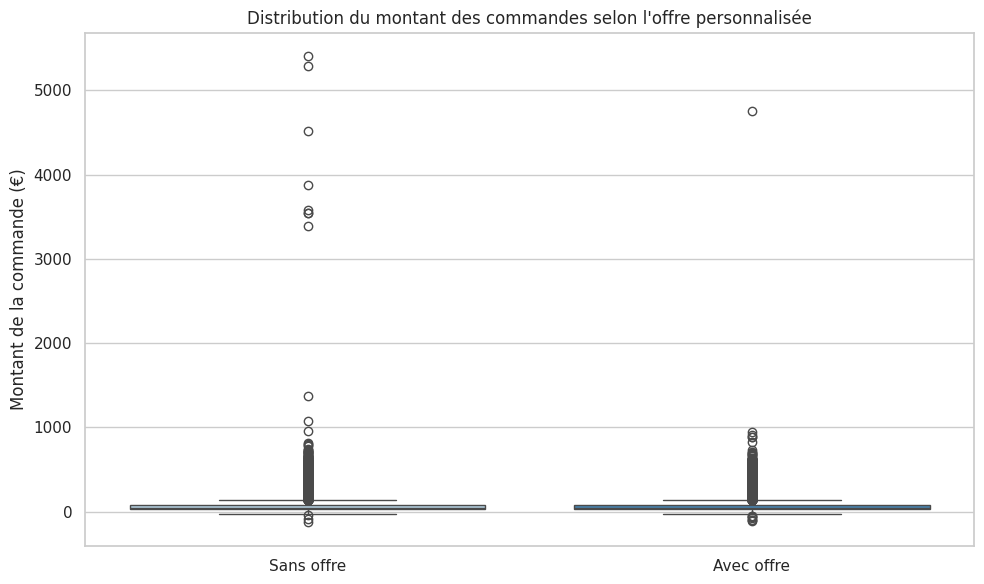

In [48]:
# Visualisation de la distribution des montants d'achat
plt.figure(figsize=(10, 6))
sns.boxplot(data=brut, x='offre_personnalisee', y='montant_eur', hue='offre_personnalisee', palette='Blues', legend=False)
plt.xticks([0, 1], ['Sans offre', 'Avec offre'])
plt.title("Distribution du montant des commandes selon l'offre personnalisée")
plt.ylabel("Montant de la commande (€)")
plt.xlabel("")
plt.tight_layout()
plt.show()

# Contrairement au taux de réachat,l'offre personnalisée n'augmente pas le montant dépensé lors de la commande.
#Le panier moyen du groupe "Avec offre" (76,44 €) est même légèrement inférieur à celui du groupe "Sans offre" (78,37 €).
#Le panier médian reste stable autour de 49 € pour les deux groupes, indiquant que la majorité des achats se situent dans la même gamme de prix.

Ce qu'il faut savoir c'est que l'offre personnalisée est un bon outil de rétention et d'engagement des clients mais elle ne permet pas de gonfler le panier d'achat immédiat.

In [49]:
# Calcul du taux de réachat par canal d'acquisition et offre personnalisée
canal_offre = brut.groupby(['canal', 'offre_personnalisee'])['rachat_90j'].agg(['count', 'mean']).reset_index()
canal_offre['rachat_pct'] = canal_offre['mean'] * 100
canal_offre['offre_label'] = canal_offre['offre_personnalisee'].map({0: 'Sans offre', 1: 'Avec offre'})

display(canal_offre.pivot(index='canal', columns='offre_label', values='rachat_pct'))

offre_label,Avec offre,Sans offre
canal,,
app,42.160000,33.035714
magasin,43.908046,34.926804
web,45.037072,33.378667


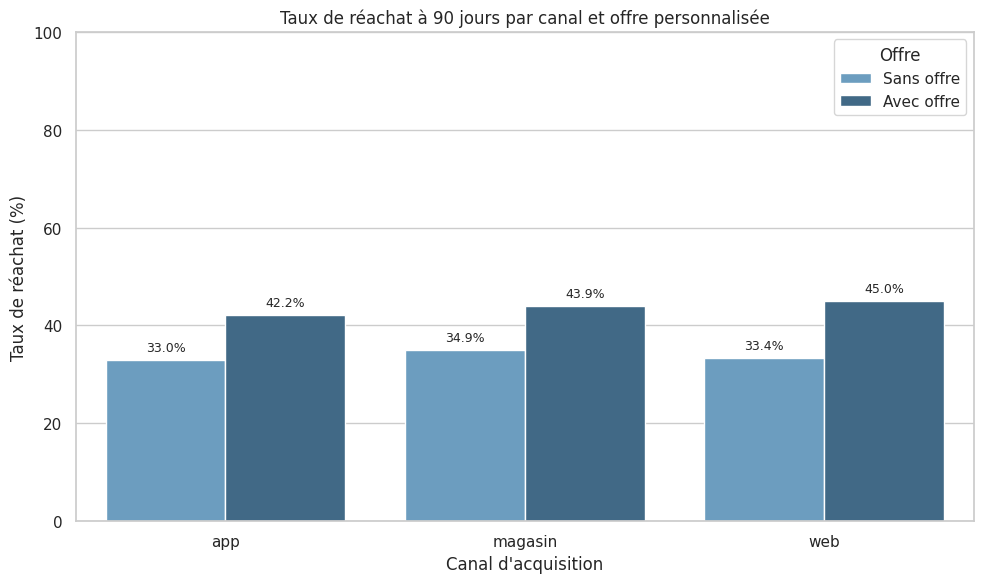

In [50]:
# Visualisation de l'impact par canal d'acquisition
plt.figure(figsize=(10, 6))
sns.barplot(data=canal_offre, x='canal', y='rachat_pct', hue='offre_label', palette='Blues_d')
plt.title("Taux de réachat à 90 jours par canal et offre personnalisée")
plt.ylabel("Taux de réachat (%)")
plt.xlabel("Canal d'acquisition")
plt.ylim(0, 100)
plt.legend(title="Offre")

# Ajout des valeurs au-dessus des barres
for p in plt.gca().patches:
    height = p.get_height()
    if height > 0:
        plt.gca().annotate(f"{height:.1f}%",
                            (p.get_x() + p.get_width() / 2., height),
                            ha='center', va='center',
                            xytext=(0, 9),
                            textcoords='offset points',
                            fontsize=9)

plt.tight_layout()
plt.show()

# If faut savoir que L'offre personnalisée améliore significativement le taux de réachat sur tous les canaux.
#De ce fait, c'est sur le canal Web que l'impact est le plus fort (+11,6 points), suivi par le Magasin (+9,0 points) et l'App (+9,2 points).